<a href="https://colab.research.google.com/github/anvithagcs24-stack/BISLAB/blob/main/1WN24CS047_BIS_WEEK5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


 FOREST FIRE MONITORING NETWORK

Optimized Communication Routes:

Sensor Node 1:
Node 1 -> Node 6 -> Base Station
Sensor Node 2:
Node 2 -> Node 5 -> Base Station
Sensor Node 3:
Node 3 -> Node 12 -> Node 9
Sensor Node 4:
Node 4 -> Node 6 -> Base Station
Sensor Node 5:
Node 5 -> Node 1 -> Base Station
Sensor Node 6:
Node 6 -> Node 4 -> Base Station
Sensor Node 7:
Node 7 -> Node 2 -> Node 5 -> Base Station
Sensor Node 8:
Node 8 -> Node 3 -> Node 12 -> Node 9
Sensor Node 9:
Node 9 -> Node 12
Sensor Node 10:
Node 10 -> Node 2 -> Node 5 -> Base Station
Sensor Node 11:
Node 11 -> Node 10 -> Node 2 -> Node 5 -> Base Station
Sensor Node 12:
Node 12 -> Node 9

 FINAL OPTIMIZATION RESULTS
Total Sensor Nodes: 12
Total Energy Consumption: 2.748 J
Total Communication Distance: 137.38
Average Remaining Battery: 2.27 J
Best Fitness Value: 19.255


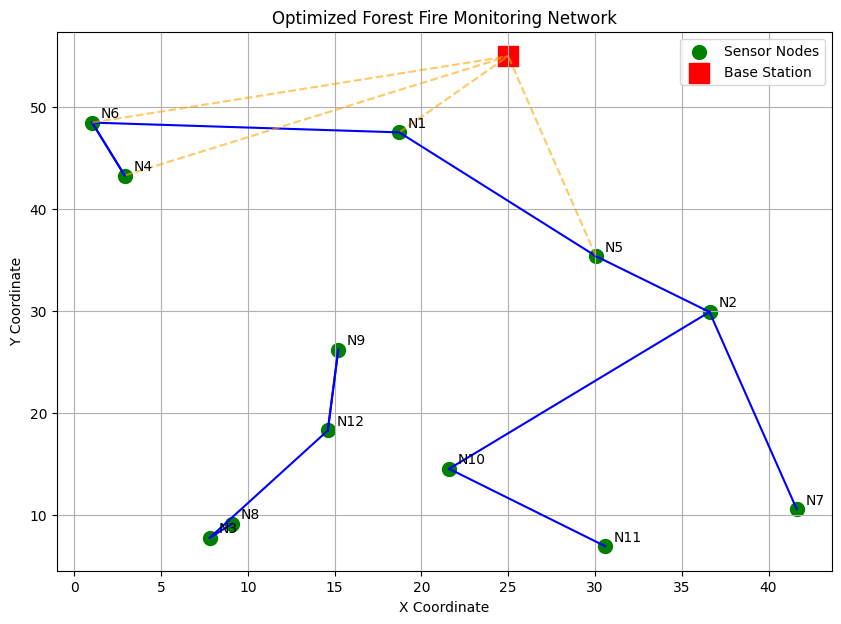

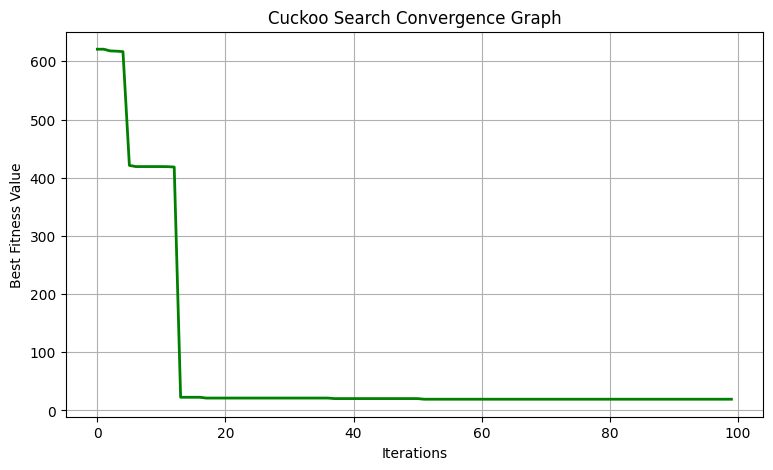

In [3]:
import numpy as np
import random
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

NUM_NODES = 12
nodes = np.random.uniform(0, 50, (NUM_NODES, 2))
base_station = np.array([25, 55])
battery = np.random.uniform(1.5, 3.0, NUM_NODES)
MAX_RANGE = 25
ENERGY_COST = 0.02
NESTS = 20
MAX_ITER = 100
PA = 0.25
ALPHA = 1.0
BETA = 2.0
GAMMA = 1.0

def distance(a, b):
    return np.linalg.norm(a - b)

def link_quality(d):
    if d > MAX_RANGE:
        return 0
    return max(0, 1 - (d / MAX_RANGE))

def fitness(solution):
    total_energy = 0
    total_distance = 0
    link_penalty = 0
    used_nodes = set()
    for i in range(NUM_NODES):
        next_node = int(solution[i])
        if next_node == i or next_node < 0 or next_node >= NUM_NODES:
            link_penalty += 100
            continue
        d = distance(nodes[i], nodes[next_node])
        quality = link_quality(d)
        if quality <= 0:
            link_penalty += 100
            continue
        energy = ENERGY_COST * d
        total_energy += energy
        total_distance += d
        used_nodes.add(i)
        used_nodes.add(next_node)
        link_penalty += (1 - quality)
    battery_penalty = sum(
        1 / (battery[i] + 0.01)
        for i in used_nodes
    )
    score = (
        ALPHA * total_energy +
        BETA * link_penalty +
        GAMMA * battery_penalty
    )
    return score

def levy_flight():
    beta = 1.5
    u = np.random.normal(0, 1)
    v = np.random.normal(0, 1)
    return u / (abs(v) ** (1 / beta) + 1e-10)

def create_routes(solution):
    routes = []
    for start in range(NUM_NODES):
        current = start
        route = [current]
        visited = {current}
        for _ in range(NUM_NODES):
            next_node = int(solution[current])
            if next_node < 0 or next_node >= NUM_NODES:
                break
            if next_node in visited:
                break
            d = distance(nodes[current], nodes[next_node])
            if link_quality(d) <= 0:
                break
            route.append(next_node)
            visited.add(next_node)
            current = next_node
            if distance(nodes[current], base_station) <= MAX_RANGE:
                route.append("Base Station")
                break
        routes.append(route)
    return routes

def cuckoo_search():
    nests = np.random.randint(
        0, NUM_NODES,
        (NESTS, NUM_NODES)
    )
    scores = np.array([
        fitness(nest) for nest in nests
    ])
    best_index = np.argmin(scores)
    best_nest = nests[best_index].copy()
    best_score = scores[best_index]
    history = []
    for iteration in range(MAX_ITER):
        for i in range(NESTS):
            new_nest = nests[i].copy()
            for j in range(NUM_NODES):
                if random.random() < 0.3:
                    step = levy_flight()
                    new_nest[j] = int(
                        abs(new_nest[j] + step * 3)
                    ) % NUM_NODES
            new_score = fitness(new_nest)
            k = random.randint(0, NESTS - 1)
            if new_score < scores[k]:
                nests[k] = new_nest
                scores[k] = new_score
        count = max(1, int(PA * NESTS))
        worst = np.argsort(scores)[-count:]
        for k in worst:
            nests[k] = np.random.randint(
                0, NUM_NODES, NUM_NODES
            )
            scores[k] = fitness(nests[k])
        best_index = np.argmin(scores)
        if scores[best_index] < best_score:
            best_score = scores[best_index]
            best_nest = nests[best_index].copy()
        history.append(best_score)
    return best_nest, best_score, history

best_solution, best_score, history = cuckoo_search()
routes = create_routes(best_solution)

print("\n===================================")
print(" FOREST FIRE MONITORING NETWORK")
print("===================================")
print("\nOptimized Communication Routes:\n")

for i, route in enumerate(routes):
    print(f"Sensor Node {i + 1}:")
    display_route = [
        f"Node {x + 1}" if isinstance(x, int) else x
        for x in route
    ]
    print(" -> ".join(display_route))

total_energy = 0
total_distance = 0
for i in range(NUM_NODES):
    j = int(best_solution[i])
    if j != i:
        d = distance(nodes[i], nodes[j])
        if link_quality(d) > 0:
            total_energy += ENERGY_COST * d
            total_distance += d

print("\n===================================")
print(" FINAL OPTIMIZATION RESULTS")
print("===================================")
print("Total Sensor Nodes:", NUM_NODES)
print("Total Energy Consumption:", round(total_energy, 3), "J")
print("Total Communication Distance:", round(total_distance, 2))
print("Average Remaining Battery:", round(np.mean(battery), 3), "J")
print("Best Fitness Value:", round(best_score, 3))

plt.figure(figsize=(10, 7))
plt.scatter(
    nodes[:, 0],
    nodes[:, 1],
    color="green",
    s=100,
    label="Sensor Nodes"
)
plt.scatter(
    base_station[0],
    base_station[1],
    color="red",
    marker="s",
    s=200,
    label="Base Station"
)
for i in range(NUM_NODES):
    plt.text(
        nodes[i][0] + 0.5,
        nodes[i][1] + 0.5,
        f"N{i+1}"
    )
    j = int(best_solution[i])
    if j != i:
        d = distance(nodes[i], nodes[j])
        if link_quality(d) > 0:
            plt.plot(
                [nodes[i][0], nodes[j][0]],
                [nodes[i][1], nodes[j][1]],
                color="blue",
                linewidth=1.5
            )
    if distance(nodes[i], base_station) <= MAX_RANGE:
        plt.plot(
            [nodes[i][0], base_station[0]],
            [nodes[i][1], base_station[1]],
            color="orange",
            linestyle="--",
            alpha=0.6
        )

plt.title("Optimized Forest Fire Monitoring Network")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(
    history,
    color="green",
    linewidth=2
)
plt.title("Cuckoo Search Convergence Graph")
plt.xlabel("Iterations")
plt.ylabel("Best Fitness Value")
plt.grid()
plt.show()

